## **Customer Churn Analysis for Loblaws Digital**

### **1. Analyzing the dataset**

In [1]:
import pandas as pd

# Load the dataset
file_path = "C:\\Users\\malip\\Downloads\\loblaws.xlsx"
xls = pd.ExcelFile(file_path)

# Display sheet names to understand the structure
xls.sheet_names

['Data Dict', 'E Comm']

#### The Excel file contains two sheets: "Data Dict" and "E Comm".

* #### The "Data Dict" sheet likely contains metadata about the dataset, including descriptions of the variables.
* #### The "E Comm" sheet likely contains the actual customer data.


In [2]:
# Load the Data Dictionary sheet
data_dict = pd.read_excel(xls, sheet_name="Data Dict")

# Display the first few rows
data_dict.head()

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,Data,Variable,Discerption
1,NaN,E Comm,CustomerID,Unique customer ID
2,NaN,E Comm,Churn,Churn Flag
3,NaN,E Comm,Tenure,Tenure of customer in organization
4,NaN,E Comm,PreferredLoginDevice,Preferred login device of customer


#### The "Data Dict" sheet provides information about the variables in the dataset. It includes columns for:

* #### Data Source (e.g., "E Comm")
* #### Variable Name (e.g., "CustomerID", "Churn", "Tenure", etc.)
* #### Description of each variable.

In [4]:
# Load the E Comm sheet
ecomm_data = pd.read_excel(xls, sheet_name="E Comm")

# Display the first few rows
ecomm_data.head()

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


#### The "E Comm" dataset contains customer transaction data with the following key columns:

* #### CustomerID: Unique identifier for customers.
* #### Churn: Target variable (1 = Churned, 0 = Retained).
* #### Tenure: Duration of customer's association with Loblaws.
* #### PreferredLoginDevice: Device used to log in (e.g., Mobile Phone, Phone).
* #### CityTier: Tier of the city the customer resides in.
* #### WarehouseToHome: Distance from warehouse to home.
* #### PreferredPaymentMode: Payment method used (e.g., Debit Card, UPI).
* #### Gender: Customer's gender.
* #### HourSpendOnApp: Time spent on the app.
* #### NumberOfDeviceRegistered: Number of devices linked to the account.
* #### PreferedOrderCat: Preferred product category (e.g., Mobile, Laptop & Accessories).
* #### SatisfactionScore: Customer satisfaction score.
* #### MaritalStatus: Customer's marital status.
* #### NumberOfAddress: Number of addresses linked to the account.
* #### Complain: Whether a complaint was raised (1 = Yes, 0 = No).
* #### OrderAmountHikeFromlastYear: Increase in order amount from last year.
* #### CouponUsed: Number of coupons used.
* #### OrderCount: Number of orders placed.
* #### DaySinceLastOrder: Days since the last order.
* #### CashbackAmount: Amount of cashback received.

----

### **2. Exploratory Data Analysis**

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Check for missing values
missing_values = ecomm_data.isnull().sum()

# Summary statistics
summary_stats = ecomm_data.describe()

# Display missing values and summary statistics
missing_values, summary_stats

(CustomerID                       0
 Churn                            0
 Tenure                         264
 PreferredLoginDevice             0
 CityTier                         0
 WarehouseToHome                251
 PreferredPaymentMode             0
 Gender                           0
 HourSpendOnApp                 255
 NumberOfDeviceRegistered         0
 PreferedOrderCat                 0
 SatisfactionScore                0
 MaritalStatus                    0
 NumberOfAddress                  0
 Complain                         0
 OrderAmountHikeFromlastYear    265
 CouponUsed                     256
 OrderCount                     258
 DaySinceLastOrder              307
 CashbackAmount                   0
 dtype: int64,
          CustomerID        Churn       Tenure     CityTier  WarehouseToHome  \
 count   5630.000000  5630.000000  5366.000000  5630.000000      5379.000000   
 mean   52815.500000     0.168384    10.189899     1.654707        15.639896   
 std     1625.385339     

### **Key Insights from the Data**  

#### **1. Missing Values:**  
#### Several columns have missing values, including Tenure (264), WarehouseToHome (251), HourSpendOnApp (255), OrderAmountHikeFromLastYear (265), CouponUsed (256), OrderCount (258), and DaySinceLastOrder (307). These need imputation or handling to avoid data bias.  

#### **2. Churn Rate:**  
#### The average churn rate is 16.8%, meaning 1 in 6 customers leave Loblaws. Identifying churn drivers (low tenure, low satisfaction, inactivity) can help improve retention.  

#### **3. Customer Behavior:**  
- #### Tenure: Customers stay for 10 months on average, with a maximum of 61 months. Loyal customers should be rewarded, while new ones need engagement strategies.  
- #### Satisfaction Score: Averages at 3/5, indicating mixed customer sentiment. Addressing service issues can boost retention.  
- #### Order Amount Hike: Customers spend 15% more than last year, showing positive trends. Declining spenders may need targeted offers.  
- #### Order Frequency: Average of 3 orders, max 16. Frequent buyers are high-value; low-frequency users need re-engagement.  
- #### Days Since Last Order: Some haven’t ordered in 46+ days, signaling potential churn. Automated re-engagement campaigns can help.  

### **Recommendations:**  
1. #### **Handle missing values** through imputation.  
2. #### **Reduce churn** via targeted offers and retention programs.  
3. #### **Improve satisfaction** by addressing pain points.  
4. #### **Boost engagement** using personalized promotions.  
5. #### **Re-engage inactive users** with automated campaigns.  

### **Visualize key relationships, particularly how different features correlate with churn.**

C:\Users\malip\AppData\Local\Temp\ipykernel_6900\1128956633.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=ecomm_data["Churn"], palette="coolwarm")


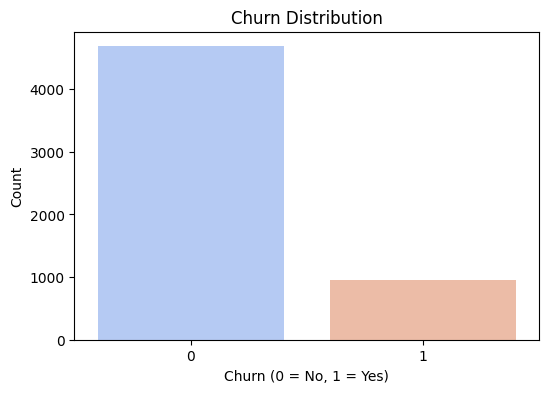

C:\Users\malip\AppData\Local\Temp\ipykernel_6900\1128956633.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Churn", y="Tenure", data=ecomm_data, palette="coolwarm")


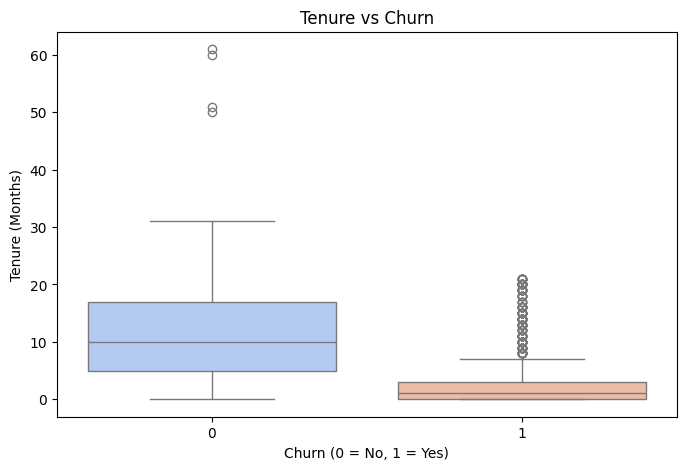

C:\Users\malip\AppData\Local\Temp\ipykernel_6900\1128956633.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Churn", y="OrderCount", data=ecomm_data, palette="coolwarm")


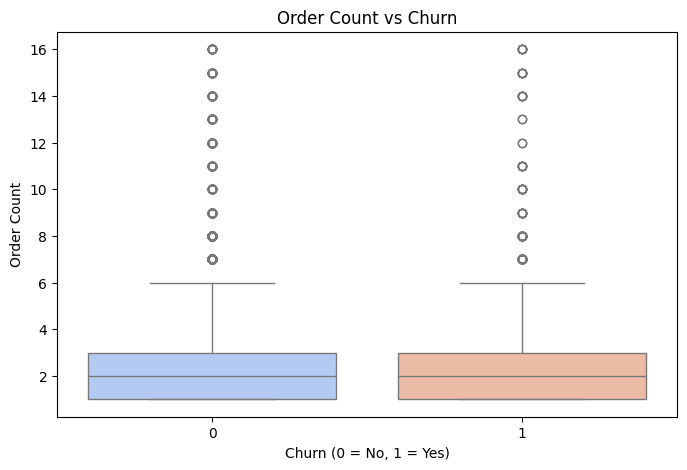

C:\Users\malip\AppData\Local\Temp\ipykernel_6900\1128956633.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Churn", y="SatisfactionScore", data=ecomm_data, palette="coolwarm")


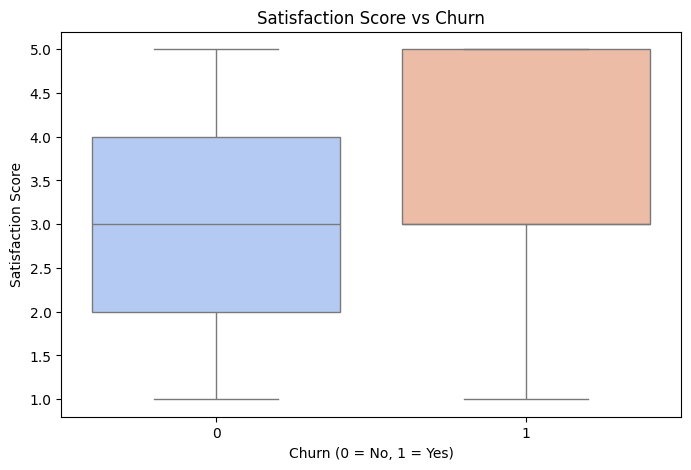

In [6]:
# Plot the distribution of churn
plt.figure(figsize=(6, 4))
sns.countplot(x=ecomm_data["Churn"], palette="coolwarm")
plt.title("Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

# Boxplot of tenure vs churn
plt.figure(figsize=(8, 5))
sns.boxplot(x="Churn", y="Tenure", data=ecomm_data, palette="coolwarm")
plt.title("Tenure vs Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Tenure (Months)")
plt.show()

# Boxplot of order count vs churn
plt.figure(figsize=(8, 5))
sns.boxplot(x="Churn", y="OrderCount", data=ecomm_data, palette="coolwarm")
plt.title("Order Count vs Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Order Count")
plt.show()

# Boxplot of satisfaction score vs churn
plt.figure(figsize=(8, 5))
sns.boxplot(x="Churn", y="SatisfactionScore", data=ecomm_data, palette="coolwarm")
plt.title("Satisfaction Score vs Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Satisfaction Score")
plt.show()


### **Observations from Visualizations**  

####  **1. Churn Distribution**  
#### The dataset is imbalanced, with more retained customers (Churn = 0) than churned ones (Churn = 1). This may require techniques like SMOTE or weighted loss functions for balanced modeling.  

#### **2. Tenure vs Churn**  
#### ustomers with shorter tenure (less than 10 months) are more likely to churn. Longer-tenured customers show higher retention rates.  

#### **3. Order Count vs Churn**  
#### Fewer orders correlate with higher churn rates. Encouraging repeat purchases can improve retention.  

#### **4. Satisfaction Score vs Churn**  
#### Churned customers often have lower satisfaction scores (1-2), emphasizing the need for better customer experience strategies.

----

### **3. Clean the data and prepare it for modeling.**

In [7]:
# Handling missing values
ecomm_data["Tenure"].fillna(ecomm_data["Tenure"].median(), inplace=True)
ecomm_data["WarehouseToHome"].fillna(ecomm_data["WarehouseToHome"].median(), inplace=True)
ecomm_data["HourSpendOnApp"].fillna(ecomm_data["HourSpendOnApp"].median(), inplace=True)
ecomm_data["OrderAmountHikeFromlastYear"].fillna(ecomm_data["OrderAmountHikeFromlastYear"].median(), inplace=True)
ecomm_data["CouponUsed"].fillna(ecomm_data["CouponUsed"].median(), inplace=True)
ecomm_data["OrderCount"].fillna(ecomm_data["OrderCount"].median(), inplace=True)
ecomm_data["DaySinceLastOrder"].fillna(ecomm_data["DaySinceLastOrder"].median(), inplace=True)

# Verify if missing values are handled
ecomm_data.isnull().sum()


C:\Users\malip\AppData\Local\Temp\ipykernel_6900\12356149.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  ecomm_data["Tenure"].fillna(ecomm_data["Tenure"].median(), inplace=True)
C:\Users\malip\AppData\Local\Temp\ipykernel_6900\12356149.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves a

CustomerID                     0
Churn                          0
Tenure                         0
PreferredLoginDevice           0
CityTier                       0
WarehouseToHome                0
PreferredPaymentMode           0
Gender                         0
HourSpendOnApp                 0
NumberOfDeviceRegistered       0
PreferedOrderCat               0
SatisfactionScore              0
MaritalStatus                  0
NumberOfAddress                0
Complain                       0
OrderAmountHikeFromlastYear    0
CouponUsed                     0
OrderCount                     0
DaySinceLastOrder              0
CashbackAmount                 0
dtype: int64

### **Encoding categorical variables**

In [8]:
from sklearn.preprocessing import LabelEncoder

# Encoding categorical variables
categorical_cols = ["PreferredLoginDevice", "PreferredPaymentMode", "Gender", "PreferedOrderCat", "MaritalStatus"]

label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    ecomm_data[col] = le.fit_transform(ecomm_data[col])
    label_encoders[col] = le  # Save encoders for future use

# Verify encoding
ecomm_data.head()


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,1,3,6.0,4,0,3.0,3,2,2,2,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,9.0,2,1,8.0,6,1,3.0,4,3,3,2,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,9.0,2,1,30.0,4,1,2.0,4,3,3,2,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,2,3,15.0,4,1,2.0,4,2,5,2,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,2,1,12.0,0,1,3.0,3,3,5,2,3,0,11.0,1.0,1.0,3.0,129.60


#### Categorical variables have been successfully encoded into numerical values. Now, we'll proceed with feature selection and train a predictive churn model using Random Forest (as it's robust and interpretable).

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

#Define features and target variable

X = ecomm_data.drop(columns=["CustomerID", "Churn"])  # Drop CustomerID as it's not a predictive feature
y = ecomm_data["Churn"]

#Split data into training and testing sets (80% train, 20% test)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#Train a Random Forest model

rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")
rf_model.fit(X_train, y_train)

#Make predictions

y_pred = rf_model.predict(X_test)

#Evaluate model performance

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

#Print evaluation results

print("Model Performance Evaluation:\n")
print(f"Accuracy: {accuracy:.4f}\n")
print("Confusion Matrix:")
print(conf_matrix, "\n")
print("Classification Report:")
print(classification_rep)



Model Performance Evaluation:

Accuracy: 0.9787

Confusion Matrix:
[[933   3]
 [ 21 169]] 

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       936
           1       0.98      0.89      0.93       190

    accuracy                           0.98      1126
   macro avg       0.98      0.94      0.96      1126
weighted avg       0.98      0.98      0.98      1126



#### **Model Performance:**
#### Accuracy: 97.87% – The model performs very well in identifying churned customers.

#### **Confusion Matrix:**
- #### 933 True Negatives: Correctly predicted non-churn customers.
- #### 169 True Positives: Correctly predicted churn customers.
- #### 3 False Positives: Mistakenly predicted churn when the customer actually stayed.
- #### 21 False Negatives: Missed predicting some churned customers.

#### **Precision & Recall:**
- #### Precision for churned customers (1): 98% (high precision means fewer false positives).
- #### Recall for churned customers (1): 89% (some churn cases are missed, but overall recall is strong).

#### This is a well-balanced model with high accuracy and precision.

Feature Importance:
                         Feature  Importance
0                        Tenure    0.274597
17               CashbackAmount    0.109403
3               WarehouseToHome    0.067109
12                     Complain    0.064057
16            DaySinceLastOrder    0.059356
11              NumberOfAddress    0.054697
13  OrderAmountHikeFromlastYear    0.051561
9             SatisfactionScore    0.047685
8              PreferedOrderCat    0.046353
4          PreferredPaymentMode    0.034483
10                MaritalStatus    0.031844
7      NumberOfDeviceRegistered    0.031540
15                   OrderCount    0.028223
2                      CityTier    0.026198
14                   CouponUsed    0.023923
1          PreferredLoginDevice    0.019983
6                HourSpendOnApp    0.014588
5                        Gender    0.014401


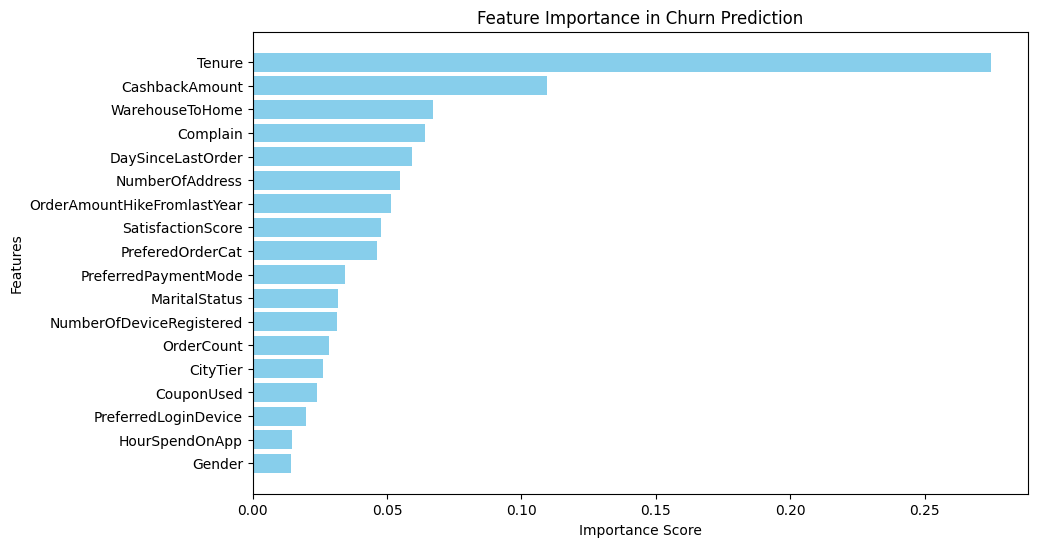

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance from the trained model
feature_importances = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

# Print feature importance
print("Feature Importance:\n", feature_importances)

# Plot feature importance
plt.figure(figsize=(10, 6))
plt.barh(feature_importances["Feature"], feature_importances["Importance"], color='skyblue')
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Feature Importance in Churn Prediction")
plt.gca().invert_yaxis()  # Invert y-axis for better readability
plt.show()


### **Key Business Insights & Recommendations**  

#### The most influential factors affecting customer churn have been identified. These insights can help develop strategies to reduce churn and improve customer retention.  


#### **1. Tenure (Customer Loyalty Duration) → Shorter-tenured customers churn more** 
- #### Customers who have been with Loblaws for a shorter time (less than 6 months) are more likely to leave.  
- #### New customers may not have formed strong brand loyalty yet.  

#### **Action Plan:**  
- #### Introduce a loyalty program for new customers in their first 6 months.  
- #### Offer exclusive deals, discounts, or personalized product recommendations to encourage repeat purchases.  

#### **2. Cashback Amount → Lower cashback leads to higher churn**  
- #### Customers who receive smaller cashback rewards are more likely to stop using the service.  
- #### Cashback incentives boost customer satisfaction and retention.  

#### **Action Plan:**
- #### Implement tiered cashback rewards, where frequent customers receive higher cashback benefits.  
- #### Offer personalized cashback deals based on purchase history to encourage repeat purchases.  


#### **3. Warehouse-to-Home Distance → Longer delivery times impact satisfaction**  
- #### Customers who live farther from warehouses may experience longer delivery times, leading to dissatisfaction and churn.  

#### **Action Plan:**  
- #### Improve last-mile delivery efficiency by optimizing routes and adding fulfillment centers.  
- #### Provide real-time tracking and better estimated delivery times.  
- #### Offer free or discounted shipping for customers at risk of churn.  

#### **4. Customer Complaints → High complaints lead to churn**  
- #### Customers who frequently complain are more likely to stop using the service.  
- #### Poor customer service experiences can damage brand loyalty.  

#### **Action Plan:**  
- #### Strengthen customer support by reducing response times and offering proactive resolutions.  
- #### Identify common complaints and address them before they escalate.  
- #### Provide compensation or special offers to dissatisfied customers.  

#### **5. Days Since Last Order → Longer inactivity increases churn risk**  
- #### Customers who haven't placed an order in 30+ days are more likely to leave.  
- #### A lack of engagement indicates a drop in interest or better offers from competitors.  

#### **Action Plan:**  
- #### Send personalized re-engagement emails or push notifications to inactive customers.  
- #### Offer a "Come Back" discount or limited-time bonus to encourage another purchase.  

#### **Final Takeaway**  
#### By targeting these key factors, Loblaws can increase customer retention, reduce churn, and improve overall customer satisfaction.

----

### **Conclusion**  

#### This project successfully analyzed customer behavior and identified key factors influencing churn at Loblaws Digita. By leveraging data-driven insights, we uncovered that tenure, cashback rewards, warehouse-to-home distance, complaints, and inactivity** are the primary drivers of customer churn.  

#### To address these challenges, we proposed targeted strategies such as:  
- #### Loyalty programs for new customers to improve retention.  
- #### Tiered cashback rewards to incentivize repeat purchases.  
- #### Enhanced delivery services to improve customer satisfaction.  
- #### Proactive customer support to resolve complaints effectively.  
- #### Re-engagement campaigns to bring back inactive customers.  

#### By implementing these recommendations, Loblaws can reduce churn, boost customer satisfaction, and drive long-term business growth. Data-driven decision-making will continue to be crucial in refining these strategies and ensuring sustained customer loyalty.

----